In [1]:
import torch
print("CUDA:", torch.cuda.is_available())

CUDA: True


In [2]:
!pip -q install librosa soundfile matplotlib numpy

In [3]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

SR = 16000
N_FFT = 512
HOP_LENGTH = 160
N_MELS = 64

In [4]:
from google.colab import files

uploaded = files.upload()

Saving zdanie.wav to zdanie.wav
Saving wyraz.wav to wyraz.wav
Saving samogloska.wav to samogloska.wav


In [5]:
def wczytaj_audio(sciezka=None):
    """Wczytuje audio do 16 kHz mono."""
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr

    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR


y1, sr1 = wczytaj_audio("samogloska.wav")
y2, sr2 = wczytaj_audio("wyraz.wav")
y3, sr3 = wczytaj_audio("zdanie.wav")


print("SAMOGŁOSKA")
print(f"Liczba próbek: {len(y1)}")
print(f"Częstotliwość próbkowania: {sr1} Hz")
print(f"Czas trwania: {len(y1) / sr1:.2f} s")

print("\nWYRAZ")
print(f"Liczba próbek: {len(y2)}")
print(f"Częstotliwość próbkowania: {sr2} Hz")
print(f"Czas trwania: {len(y2) / sr2:.2f} s")

print("\nZDANIE")
print(f"Liczba próbek: {len(y3)}")
print(f"Częstotliwość próbkowania: {sr3} Hz")
print(f"Czas trwania: {len(y3) / sr3:.2f} s")

SAMOGŁOSKA
Liczba próbek: 14123
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 0.88 s

WYRAZ
Liczba próbek: 19584
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 1.22 s

ZDANIE
Liczba próbek: 33238
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.08 s


In [6]:
from IPython.display import Audio, display

print("Samogłoska:")
display(Audio(y1, rate=sr1))

print("Wyraz:")
display(Audio(y2, rate=sr2))

print("Zdanie:")
display(Audio(y3, rate=sr3))

Samogłoska:


Wyraz:


Zdanie:


In [7]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)


def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=n_mfcc,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )


# Samogłoska
S1_db = log_mel(y1, sr1)
M1 = mfcc(y1, sr1)

# Wyraz
S2_db = log_mel(y2, sr2)
M2 = mfcc(y2, sr2)

# Zdanie
S3_db = log_mel(y3, sr3)
M3 = mfcc(y3, sr3)


print("SAMOGŁOSKA")
print(f"Kształt log-mel: {S1_db.shape}")
print(f"Kształt MFCC: {M1.shape}")

print("\nWYRAZ")
print(f"Kształt log-mel: {S2_db.shape}")
print(f"Kształt MFCC: {M2.shape}")

print("\nZDANIE")
print(f"Kształt log-mel: {S3_db.shape}")
print(f"Kształt MFCC: {M3.shape}")

SAMOGŁOSKA
Kształt log-mel: (64, 89)
Kształt MFCC: (13, 89)

WYRAZ
Kształt log-mel: (64, 123)
Kształt MFCC: (13, 123)

ZDANIE
Kształt log-mel: (64, 208)
Kształt MFCC: (13, 208)


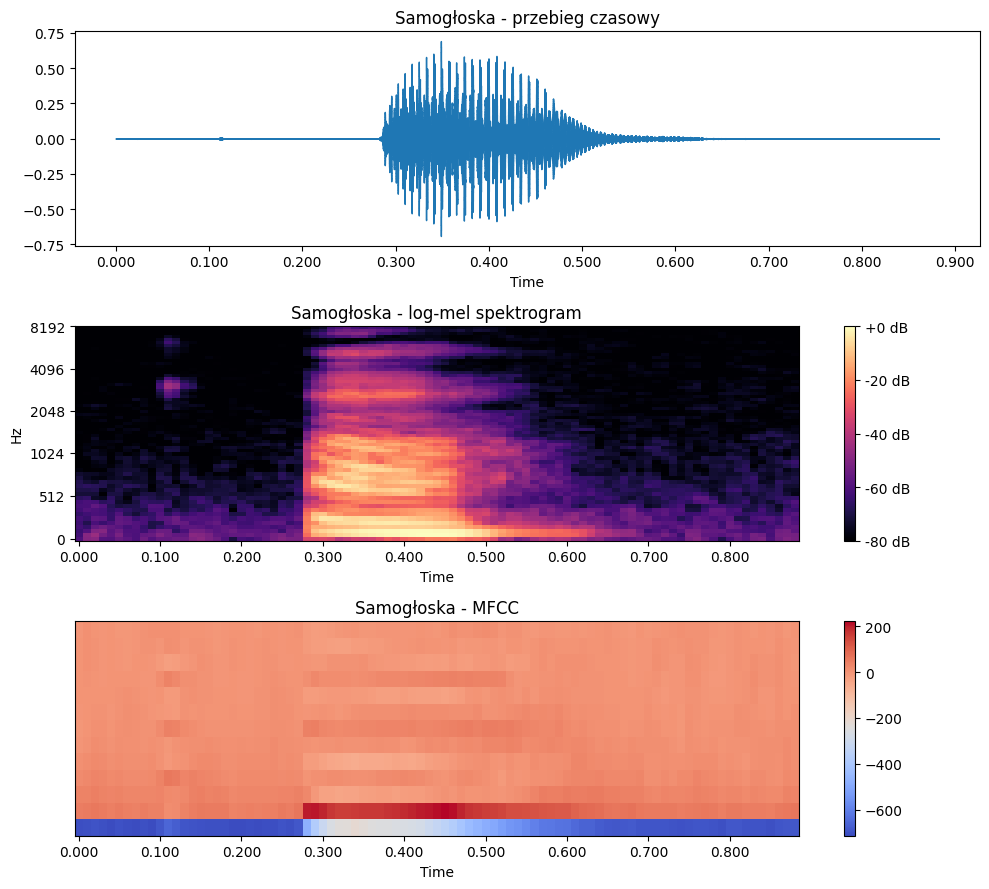

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y1, sr=sr1, ax=ax[0])
ax[0].set_title("Samogłoska - przebieg czasowy")

img1 = librosa.display.specshow(
    S1_db,
    sr=sr1,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=ax[1]
)
ax[1].set_title("Samogłoska - log-mel spektrogram")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M1,
    sr=sr1,
    hop_length=HOP_LENGTH,
    x_axis="time",
    ax=ax[2]
)
ax[2].set_title("Samogłoska - MFCC")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

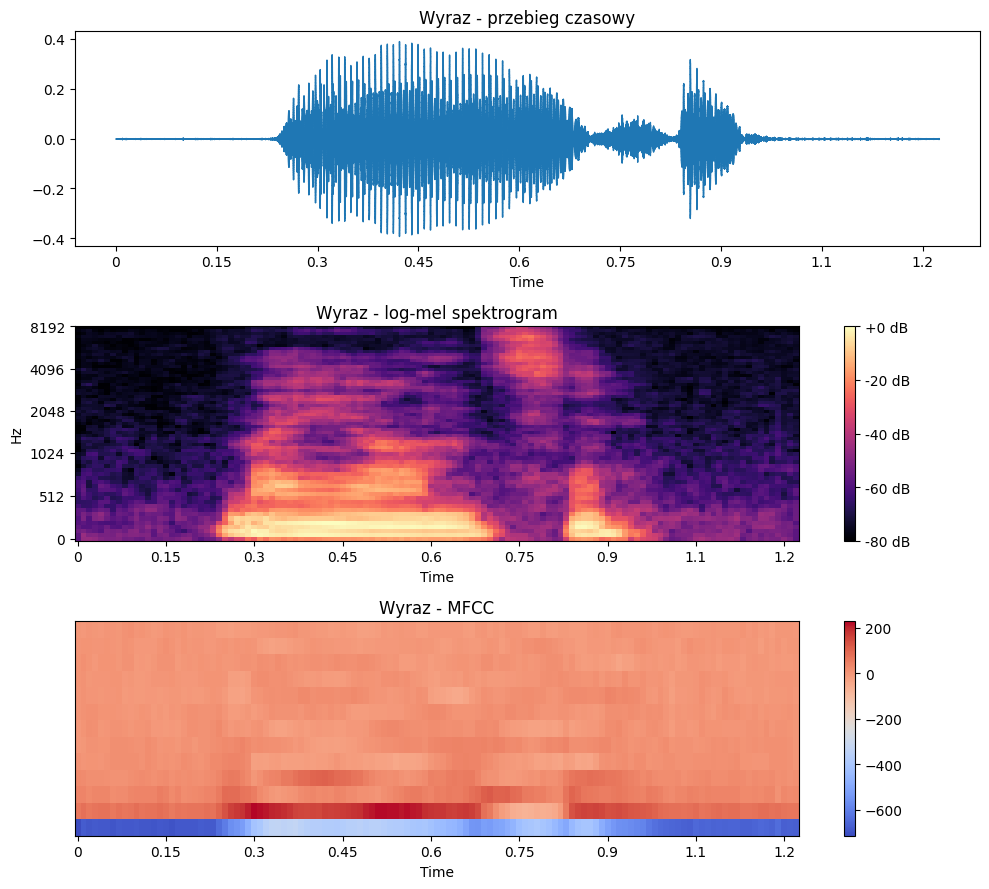

In [9]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y2, sr=sr2, ax=ax[0])
ax[0].set_title("Wyraz - przebieg czasowy")

img1 = librosa.display.specshow(
    S2_db,
    sr=sr2,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=ax[1]
)
ax[1].set_title("Wyraz - log-mel spektrogram")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M2,
    sr=sr2,
    hop_length=HOP_LENGTH,
    x_axis="time",
    ax=ax[2]
)
ax[2].set_title("Wyraz - MFCC")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

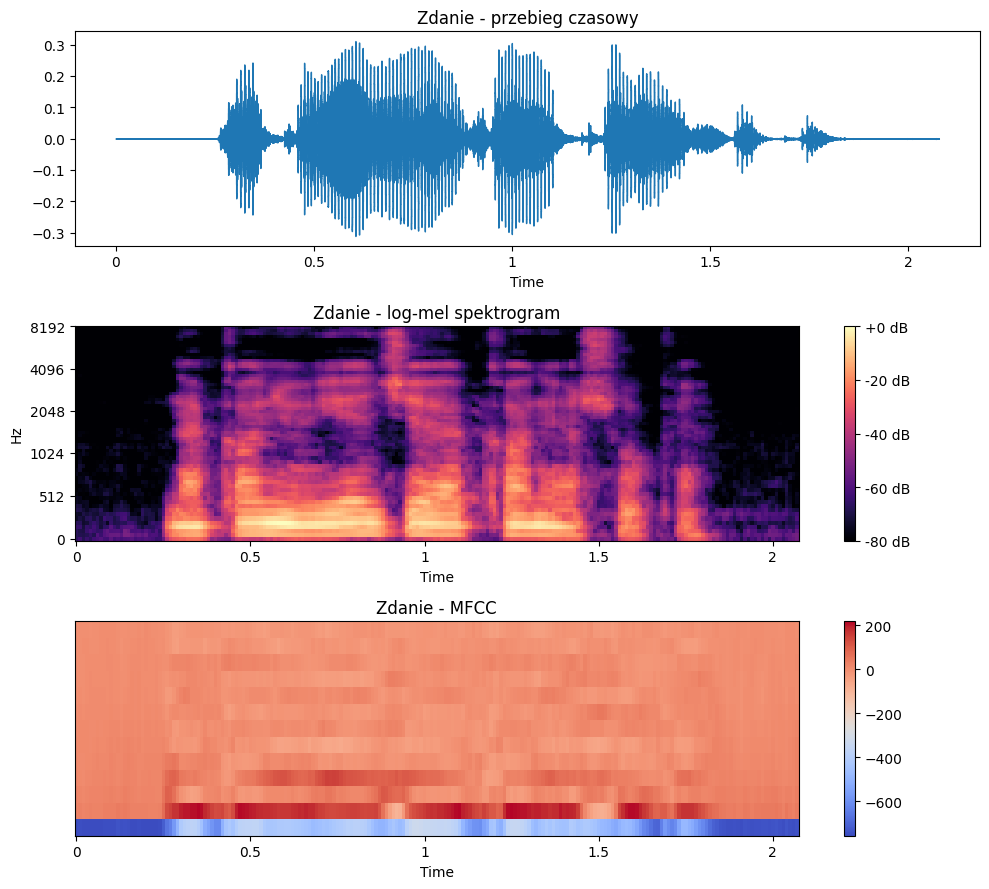

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y3, sr=sr3, ax=ax[0])
ax[0].set_title("Zdanie - przebieg czasowy")

img1 = librosa.display.specshow(
    S3_db,
    sr=sr3,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=ax[1]
)
ax[1].set_title("Zdanie - log-mel spektrogram")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M3,
    sr=sr3,
    hop_length=HOP_LENGTH,
    x_axis="time",
    ax=ax[2]
)
ax[2].set_title("Zdanie - MFCC")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

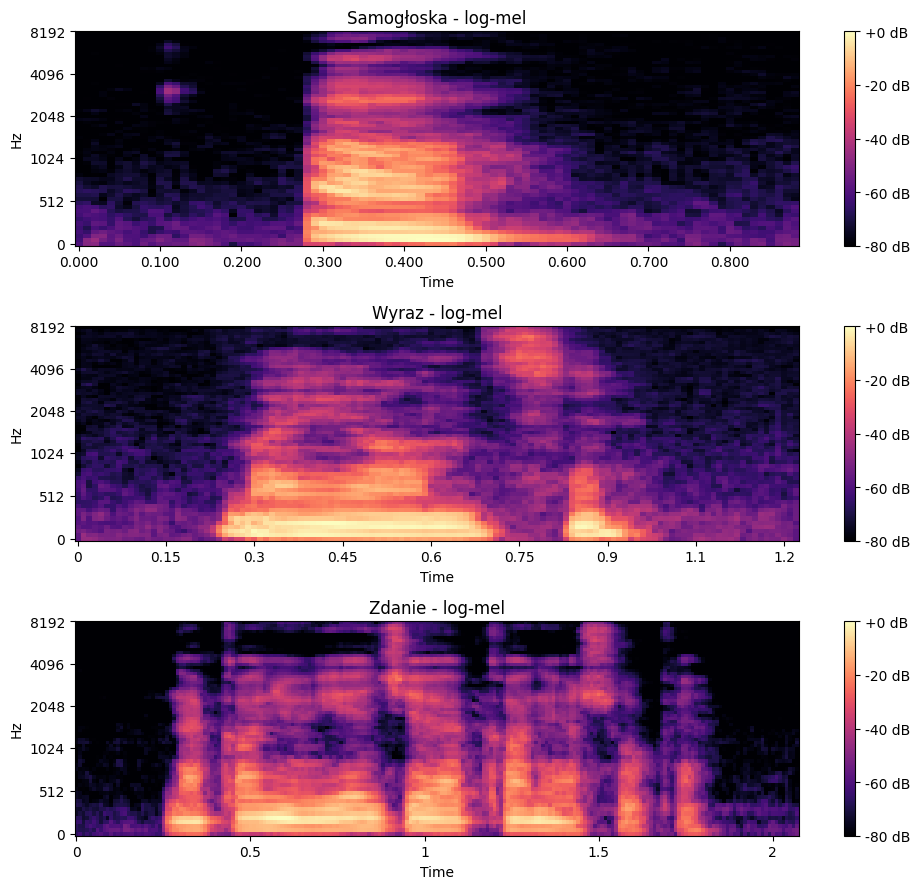

In [11]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

img1 = librosa.display.specshow(
    S1_db,
    sr=sr1,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=ax[0]
)
ax[0].set_title("Samogłoska - log-mel")
fig.colorbar(img1, ax=ax[0], format="%+2.0f dB")

img2 = librosa.display.specshow(
    S2_db,
    sr=sr2,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=ax[1]
)
ax[1].set_title("Wyraz - log-mel")
fig.colorbar(img2, ax=ax[1], format="%+2.0f dB")

img3 = librosa.display.specshow(
    S3_db,
    sr=sr3,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    ax=ax[2]
)
ax[2].set_title("Zdanie - log-mel")
fig.colorbar(img3, ax=ax[2], format="%+2.0f dB")

plt.tight_layout()
plt.show()

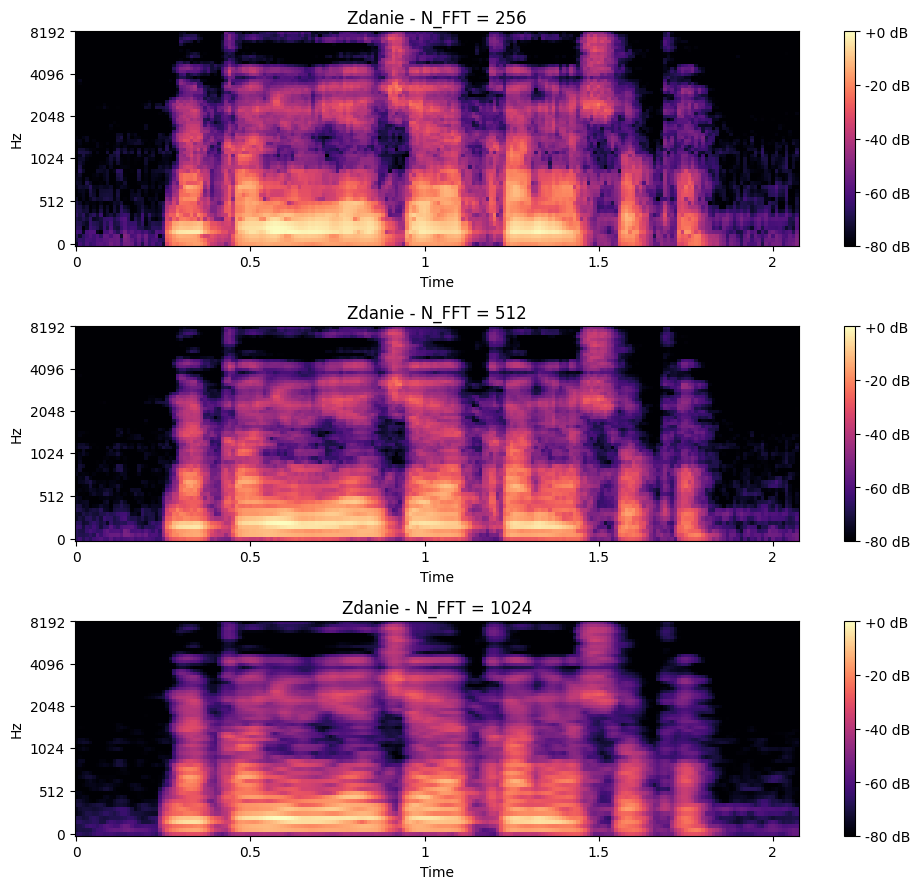

In [12]:
N_FFT_VALUES = [256, 512, 1024]

fig, ax = plt.subplots(3, 1, figsize=(10, 9))

for i, n_fft in enumerate(N_FFT_VALUES):

    S_db = log_mel(
        y3,
        sr3,
        n_fft=n_fft,
        hop_length=160
    )

    img = librosa.display.specshow(
        S_db,
        sr=sr3,
        hop_length=160,
        x_axis="time",
        y_axis="mel",
        ax=ax[i]
    )

    ax[i].set_title(f"Zdanie - N_FFT = {n_fft}")
    fig.colorbar(img, ax=ax[i], format="%+2.0f dB")

plt.tight_layout()
plt.show()

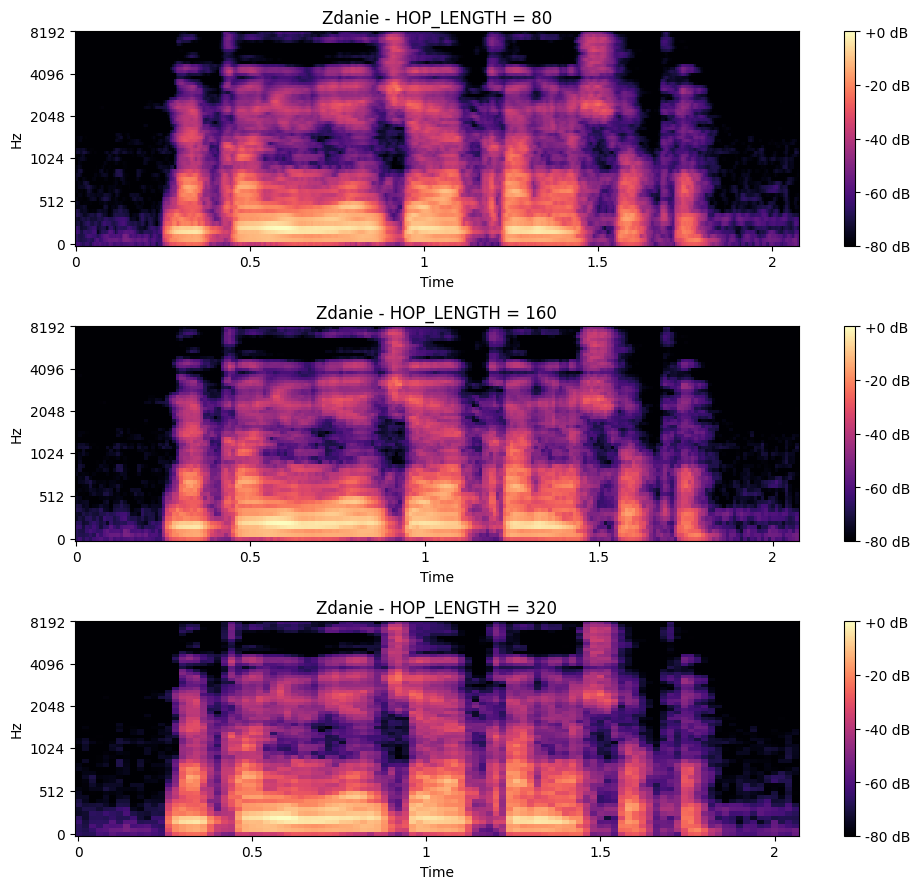

In [13]:
HOP_VALUES = [80, 160, 320]

fig, ax = plt.subplots(3, 1, figsize=(10, 9))

for i, hop in enumerate(HOP_VALUES):

    S_db = log_mel(
        y3,
        sr3,
        n_fft=512,
        hop_length=hop
    )

    img = librosa.display.specshow(
        S_db,
        sr=sr3,
        hop_length=hop,
        x_axis="time",
        y_axis="mel",
        ax=ax[i]
    )

    ax[i].set_title(f"Zdanie - HOP_LENGTH = {hop}")
    fig.colorbar(img, ax=ax[i], format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [14]:
print("Wpływ HOP_LENGTH na liczbę ramek:\n")

for hop in [80, 160, 320]:

    S_db = log_mel(
        y3,
        sr3,
        n_fft=512,
        hop_length=hop
    )

    print(f"HOP_LENGTH = {hop}")
    print(f"Kształt log-mel: {S_db.shape}")
    print(f"Liczba ramek: {S_db.shape[1]}")
    print()

Wpływ HOP_LENGTH na liczbę ramek:

HOP_LENGTH = 80
Kształt log-mel: (64, 416)
Liczba ramek: 416

HOP_LENGTH = 160
Kształt log-mel: (64, 208)
Liczba ramek: 208

HOP_LENGTH = 320
Kształt log-mel: (64, 104)
Liczba ramek: 104

